# AI624 Assignment 3 — Quantization
## 0. Experimental Setup
GPT-2 small (`openai-community/gpt2`) on WikiText-2 (`wikitext-2-raw-v1`), sequence length 128.
128 training blocks for calibration (fixed seed), validation for tuning, test for final results.

## Imports & settings

In [4]:
%pip install torch transformers datasets psutil pandas matplotlib

  Using cached torch-2.14.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (39 kB)
  Using cached setuptools-84.0.0-py3-none-any.whl.metadata (6.6 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.7-py3-none-any.whl.metadata (6.7 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
  Using cached markupsafe-3.0.4-cp314-cp314-macosx_11_0_arm64.whl.metadata (2.7 kB)
Using cached torch-2.14.1-cp314-cp314-macosx_14_0_arm64.whl (127.3 MB)
Using cached networkx-3.7-py3-none-any.whl (2.1 MB)
Using cached setuptools-84.0.0-py3-none-any.whl (818 kB)
Using cached sympy-1.14.0-py3-none-any.whl (6.3 MB)
Using cached mpmath-1.3.0-py3-none-any.whl (536 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached markupsafe-3.0.4-cp314-cp314-macosx_11_0_arm64.whl (12 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [torch]32m6/7 [torch]]x]s]
Note: you may need to restart the k

In [13]:
import math, json, random, platform, hashlib
import numpy as np, pandas as pd
import torch, torch.nn.functional as F
import transformers, datasets
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
from datasets import load_dataset
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Patch

# ---------- Fixed settings (same for every experiment) ----------
SEED       = 42
SEQ_LEN    = 128
N_CALIB    = 128
EVAL_BS    = 8      # evaluation + calibration batch size
PROFILE_BS = 1      # profiling batch size
MODEL_ID   = "openai-community/gpt2"

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"      
else:
    DEVICE = "cpu"

## Functions

In [14]:
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if DEVICE == "mps":  torch.mps.manual_seed(s)
    if DEVICE == "cuda": torch.cuda.manual_seed_all(s)


def sync():
    if DEVICE == "mps":    torch.mps.synchronize()
    elif DEVICE == "cuda": torch.cuda.synchronize()


def load_fp32_model():
    model = GPT2LMHeadModel.from_pretrained(MODEL_ID, torch_dtype=torch.float32)
    model = model.to(DEVICE).eval()
    assert all(p.dtype == torch.float32 for p in model.parameters()) and not model.training
    return model


def build_blocks(texts, tok):
    texts = [t for t in texts if t.strip()]
    encoded = tok(texts, add_special_tokens=False)["input_ids"]
    ids = []
    for i, e in enumerate(encoded):
        if i: ids.append(tok.eos_token_id)
        ids.extend(e)
    n = len(ids) // SEQ_LEN
    blocks = torch.tensor(ids[: n * SEQ_LEN], dtype=torch.long).view(n, SEQ_LEN)
    info = {"non_empty_examples": len(texts), "tokens": len(ids), "blocks": n,
            "discarded_tokens": len(ids) - n * SEQ_LEN, "scored_targets": n * (SEQ_LEN - 1)}
    return blocks, info


def fingerprint(blocks):
    return hashlib.sha256(blocks.numpy().tobytes()).hexdigest()[:16]


@torch.no_grad()
def evaluate_lm(model, blocks, bs=EVAL_BS):
    model.eval()
    nll, correct, n = 0.0, 0, 0
    for i in range(0, len(blocks), bs):
        x = blocks[i:i+bs].to(DEVICE)
        logits = model(input_ids=x, use_cache=False).logits[:, :-1].float()  # predict pos 1..127
        y = x[:, 1:]                                                          # true next tokens
        nll += F.cross_entropy(logits.flatten(0, 1), y.flatten(), reduction="sum").item()
        correct += (logits.argmax(-1) == y).sum().item()
        n += y.numel()
    return {"accuracy_%": 100 * correct / n, "nll": nll / n,
            "ppl": math.exp(nll / n), "scored_targets": n}

## main Calling functions

In [7]:
set_seed()

tok = GPT2TokenizerFast.from_pretrained(MODEL_ID)
ds  = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

train_blocks, train_info = build_blocks(ds["train"]["text"],      tok)
val_blocks,   val_info   = build_blocks(ds["validation"]["text"], tok)
test_blocks,  test_info  = build_blocks(ds["test"]["text"],       tok)

# Fixed calibration set: 128 train blocks, reused by every PTQ method
g = torch.Generator().manual_seed(SEED)
calib_idx    = torch.randperm(len(train_blocks), generator=g)[:N_CALIB]
calib_blocks = train_blocks[calib_idx]

# Record everything needed to reproduce
setup_record = {
    "model": MODEL_ID, "dataset": "Salesforce/wikitext / wikitext-2-raw-v1",
    "seq_len": SEQ_LEN, "seed": SEED, "n_calib": N_CALIB,
    "calib_indices": calib_idx.tolist(),
    "eval_batch_size": EVAL_BS, "profile_batch_size": PROFILE_BS,
    "precision": "FP32", "use_cache": False, "device": DEVICE,
    "fingerprints": {k: fingerprint(b) for k, b in
                     [("train", train_blocks), ("validation", val_blocks),
                      ("test", test_blocks), ("calibration", calib_blocks)]},
    "versions": {"python": platform.python_version(), "torch": torch.__version__,
                 "transformers": transformers.__version__, "datasets": datasets.__version__,
                 "macOS": platform.mac_ver()[0], "chip": platform.processor()},
}
json.dump(setup_record, open("setup_record.json", "w"), indent=2)

# Check the model loads correctly
_m = load_fp32_model()
n_params = sum(p.numel() for p in _m.parameters())   # tied weights counted once
del _m

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 10122.41it/s]


### Results

In [8]:
print("=== Dataset blocks (128 tokens per block, 127 scored targets per block) ===")
display(pd.DataFrame([train_info, val_info, test_info], index=["train", "validation", "test"]))

print("\n=== Settings ===")
print(f"Model                {MODEL_ID}  ({n_params/1e6:.2f} M unique parameters)")
print(f"Calibration          {N_CALIB} train blocks, seed {SEED} (indices in setup_record.json)")
print(f"Batch size           eval/calib = {EVAL_BS}, profiling = {PROFILE_BS}")
print(f"Inference            FP32, eval mode, no gradients, use_cache=False")
print(f"Device               {DEVICE}")

print("\n=== Block fingerprints (must not change between experiments) ===")
for k, v in setup_record["fingerprints"].items():
    print(f"{k:12s} {v}")

print("\n=== Environment ===")
for k, v in setup_record["versions"].items():
    print(f"{k:13s} {v}")

=== Dataset blocks (128 tokens per block, 127 scored targets per block) ===


,non_empty_examples,tokens,blocks,discarded_tokens,scored_targets
train,23767,2415650,18872,34,2396744
validation,2461,249749,1951,21,247777
test,2891,286177,2235,97,283845



=== Settings ===
Model                openai-community/gpt2  (124.44 M unique parameters)
Calibration          128 train blocks, seed 42 (indices in setup_record.json)
Batch size           eval/calib = 8, profiling = 1
Inference            FP32, eval mode, no gradients, use_cache=False
Device               mps

=== Block fingerprints (must not change between experiments) ===
train        c09f281474a95eeb
validation   c033bf55a2004da2
test         cde0f2d28878e25e
calibration  04d77d5854d0d81f

=== Environment ===
python        3.14.2
torch         2.14.1
transformers  5.20.1
datasets      5.1.0
macOS         26.6.2
chip          arm


# 1 Task 1: GPT-2 Baseline and Model Profiling 

##  Task 1.1 — Model Architecture and Quantization Scope

In [15]:
PROJS = ["attn.c_attn", "attn.c_proj", "mlp.c_fc", "mlp.c_proj"]   # quantized in Task 2

def get_proj(model, i, name):
    block = model.transformer.h[i]
    for part in name.split("."):
        block = getattr(block, part)
    return block

@torch.no_grad()
def check_projections(model):
    rows = []
    for name in PROJS:
        layer = get_proj(model, 0, name)
        W, b = layer.weight, layer.bias
        x = torch.randn(1, SEQ_LEN, W.shape[0], device=DEVICE)
        diff = (layer(x) - (x @ W + b)).abs().max().item()
        rows.append({"module": name, "type": type(layer).__name__,
                     "weight (in, out)": tuple(W.shape), "bias": tuple(b.shape),
                     "output channels": W.shape[1], "max diff": diff})
    return pd.DataFrame(rows)




os.makedirs("figures", exist_ok=True)
Q_COLOR, FP_COLOR, RES_COLOR = "#E07B39", "#DDE3EA", "#2B6CB0"   # quantized / FP32 / residual

def _box(ax, x, y, w, h, text, quant=False):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.02",
                                fc=Q_COLOR if quant else FP_COLOR, ec="#333333", lw=1))
    ax.text(x, y, text, ha="center", va="center", fontsize=9,
            color="white" if quant else "#222222", fontweight="bold" if quant else "normal")

def _arrow(ax, x0, y0, x1, y1, color="#333333", style="-|>", **kw):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle=style, color=color, lw=1.2, **kw))

def _legend(ax, q_label="Quantized in Task 2 (weights + input activations)", **kw):
    ax.legend(handles=[Patch(fc=Q_COLOR, ec="#333", label=q_label),
                       Patch(fc=FP_COLOR, ec="#333", label="Kept in FP32")],
              frameon=False, fontsize=9, **kw)

def _save(fig, path):
    fig.tight_layout()
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()


def plot_model_overview(save="figures/t11_model_overview.png"):
    """Whole GPT-2: token IDs -> embeddings -> 12 blocks -> ln_f -> tied lm_head -> logits."""
    steps = [("Token IDs\n(B, 128)", False),
             ("wte + wpe\nembeddings\n(B, 128, 768)", False),
             ("Transformer\nblock × 12", True),
             ("ln_f\nfinal LayerNorm", False),
             ("lm_head\n768 → 50257", False),
             ("Logits\n(B, 128, 50257)", False)]
    W, H, gap = 1.9, 1.3, 2.5
    xs = [i * gap for i in range(len(steps))]
    fig, ax = plt.subplots(figsize=(13, 3.8))
    for (text, q), x in zip(steps, xs):
        _box(ax, x, 0, W, H, text, q)
    for x0, x1 in zip(xs[:-1], xs[1:]):
        _arrow(ax, x0 + W/2, 0, x1 - W/2, 0)
    _arrow(ax, xs[4], H/2, xs[1], H/2, color=RES_COLOR, style="<->",
           ls="--", connectionstyle="arc3,rad=0.25")                     # weight tying
    ax.text((xs[1] + xs[4]) / 2, H/2 + 1.15, "tied: lm_head reuses the wte matrix (50257 × 768)",
            ha="center", color=RES_COLOR, fontsize=9)
    ax.set_xlim(xs[0] - W, xs[-1] + W); ax.set_ylim(-1.6, 2.2); ax.axis("off")
    ax.set_title("GPT-2 small — overall structure", fontsize=12)
    _legend(ax, q_label="Contains the 4 quantized projections", loc="lower center", ncol=2)
    _save(fig, save)


def plot_block_diagram(save="figures/t11_block_diagram.png"):
    """One Transformer block in execution order; quantized projections highlighted."""
    steps = [("Input x   (B, 128, 768)", False),
             ("ln_1   (LayerNorm)", False),
             ("attn.c_attn   768 → 2304   (Q, K, V)", True),
             (r"$QK^T/\sqrt{64}$  + causal mask", False),
             ("softmax", False),
             ("× V   (12 heads, concat → 768)", False),
             ("attn.c_proj   768 → 768", True),
             ("+  residual", False),
             ("ln_2   (LayerNorm)", False),
             ("mlp.c_fc   768 → 3072", True),
             ("GELU", False),
             ("mlp.c_proj   3072 → 768", True),
             ("+  residual", False),
             ("Output   (B, 128, 768)", False)]
    W, H = 4.2, 0.55
    ys = [-i for i in range(len(steps))]
    fig, ax = plt.subplots(figsize=(8, 11))

    for a, b, label in [(1, 7, "Attention sub-layer"), (8, 12, "MLP sub-layer")]:
        ax.add_patch(plt.Rectangle((-W/2 - 0.6, ys[b] - 0.45), W + 1.2, ys[a] - ys[b] + 0.9,
                                   fc="#F4F6F9", ec="#C9D1DB", zorder=0))
        ax.text(-W/2 - 0.35, (ys[a] + ys[b]) / 2, label, rotation=90,
                ha="center", va="center", fontsize=10, color="#555555")

    for (text, q), y in zip(steps, ys):
        _box(ax, 0, y, W, H, text, q)
    for y0, y1 in zip(ys[:-1], ys[1:]):
        _arrow(ax, 0, y0 - H/2, 0, y1 + H/2)

    for src, dst, xr in [(0, 7, W/2 + 0.9), (7, 12, W/2 + 1.3)]:     # residual (skip) paths
        ax.plot([W/2, xr, xr], [ys[src], ys[src], ys[dst]], color=RES_COLOR, lw=1.4)
        _arrow(ax, xr, ys[dst], W/2, ys[dst], color=RES_COLOR)
        ax.text(xr + 0.12, (ys[src] + ys[dst]) / 2, "residual", rotation=90,
                va="center", fontsize=9, color=RES_COLOR)

    ax.set_xlim(-W/2 - 0.8, W/2 + 1.8); ax.set_ylim(ys[-1] - 1.3, 0.7); ax.axis("off")
    ax.set_title("One GPT-2 block (repeated 12×) — order of operations", fontsize=12)
    _legend(ax, loc="lower center", ncol=1)
    fig.text(0.5, 0.01, "Dropout layers are identity in eval mode and are omitted.",
             ha="center", fontsize=8, color="#666666")
    _save(fig, save)


def plot_param_breakdown(model, save="figures/t11_param_breakdown.png"):
    """Where the 124.44 M unique parameters are, and how many get quantized."""
    groups = {f"{k} (×12)": 0 for k in PROJS}
    groups.update({"wte (token emb., tied lm_head)": 0, "wpe (positional emb.)": 0,
                   "biases + LayerNorms": 0})
    for name, p in model.named_parameters():                    # tied lm_head counted once
        key = next((k for k in PROJS if name.endswith(f".{k}.weight")), None)
        if key:              groups[f"{key} (×12)"] += p.numel()
        elif "wte" in name:  groups["wte (token emb., tied lm_head)"] += p.numel()
        elif "wpe" in name:  groups["wpe (positional emb.)"] += p.numel()
        else:                groups["biases + LayerNorms"] += p.numel()

    names = list(groups)[::-1]
    vals = [groups[n] / 1e6 for n in names]
    is_q = [n.split()[0] in PROJS for n in names]
    total, q_total = sum(vals), sum(v for v, q in zip(vals, is_q) if q)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.barh(names, vals, color=[Q_COLOR if q else FP_COLOR for q in is_q], edgecolor="#333")
    for b, v in zip(bars, vals):
        ax.text(b.get_width() + 0.4, b.get_y() + b.get_height() / 2, f"{v:.2f} M", va="center", fontsize=9)
    ax.set_xlim(0, max(vals) * 1.2)
    ax.set_xlabel("Parameters (millions)")
    ax.set_title(f"GPT-2 parameters: {q_total:.2f} M of {total:.2f} M "
                 f"({100 * q_total / total:.1f}%) are quantized in Task 2", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    _legend(ax, loc="lower right")
    _save(fig, save)

## run helper functions

In [11]:
model = load_fp32_model()
cfg = model.config

total_params = sum(p.numel() for p in model.parameters())
quant_params = sum(get_proj(model, i, n).weight.numel()
                   for i in range(cfg.n_layer) for n in PROJS)
tied = model.lm_head.weight.data_ptr() == model.transformer.wte.weight.data_ptr()

proj_df = check_projections(model)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 7277.34it/s]


## results

In [12]:
print("=== GPT-2 small ===")
print(f"Blocks: {cfg.n_layer} | Hidden: {cfg.n_embd} | Heads: {cfg.n_head} | "
      f"MLP size: {4 * cfg.n_embd} | Vocab: {cfg.vocab_size}")
print(f"Unique parameters: {total_params/1e6:.2f} M | LM head tied to embedding: {tied}")

print("\n=== One block (order: ln_1 → attn → ln_2 → mlp) ===")
print(model.transformer.h[0])

print("\n=== The 4 projections to quantize (same in all 12 blocks) ===")
display(proj_df)
print("Conv1D stores weight as (in, out) → one output channel = one column → scales over dim 0")

print(f"\nQuantized weights: {quant_params/1e6:.2f} M of {total_params/1e6:.2f} M "
      f"({100*quant_params/total_params:.1f}%)")

=== GPT-2 small ===
Blocks: 12 | Hidden: 768 | Heads: 12 | MLP size: 3072 | Vocab: 50257
Unique parameters: 124.44 M | LM head tied to embedding: True

=== One block (order: ln_1 → attn → ln_2 → mlp) ===
GPT2Block(
  (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (attn): GPT2Attention(
    (c_attn): Conv1D(nf=2304, nx=768)
    (c_proj): Conv1D(nf=768, nx=768)
    (attn_dropout): Dropout(p=0.1, inplace=False)
    (resid_dropout): Dropout(p=0.1, inplace=False)
  )
  (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  (mlp): GPT2MLP(
    (c_fc): Conv1D(nf=3072, nx=768)
    (c_proj): Conv1D(nf=768, nx=3072)
    (act): NewGELUActivation()
    (dropout): Dropout(p=0.1, inplace=False)
  )
)

=== The 4 projections to quantize (same in all 12 blocks) ===


,module,type,"weight (in, out)",bias,output channels,max diff
0,attn.c_attn,Conv1D,"(768, 2304)","(2304,)",2304,0.0
1,attn.c_proj,Conv1D,"(768, 768)","(768,)",768,0.0
2,mlp.c_fc,Conv1D,"(768, 3072)","(3072,)",3072,0.0
3,mlp.c_proj,Conv1D,"(3072, 768)","(768,)",768,0.0


Conv1D stores weight as (in, out) → one output channel = one column → scales over dim 0

Quantized weights: 84.93 M of 124.44 M (68.3%)


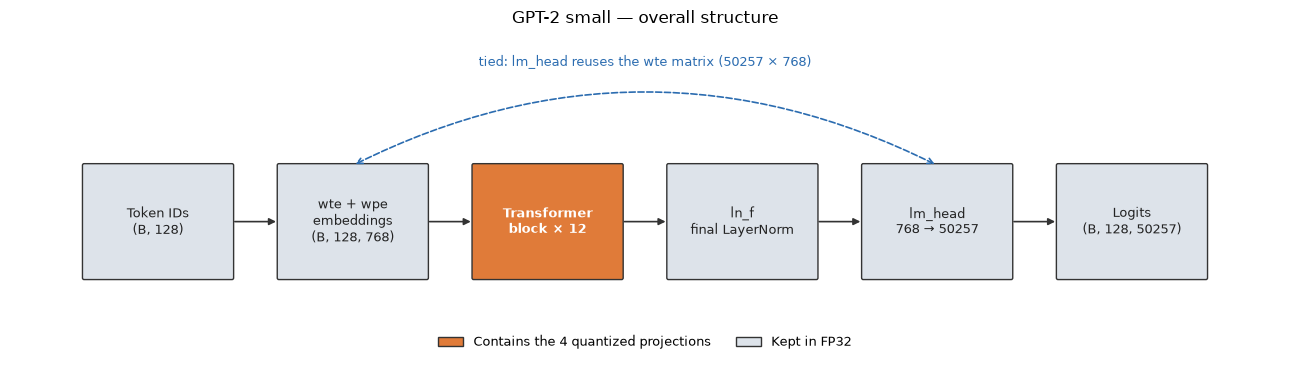

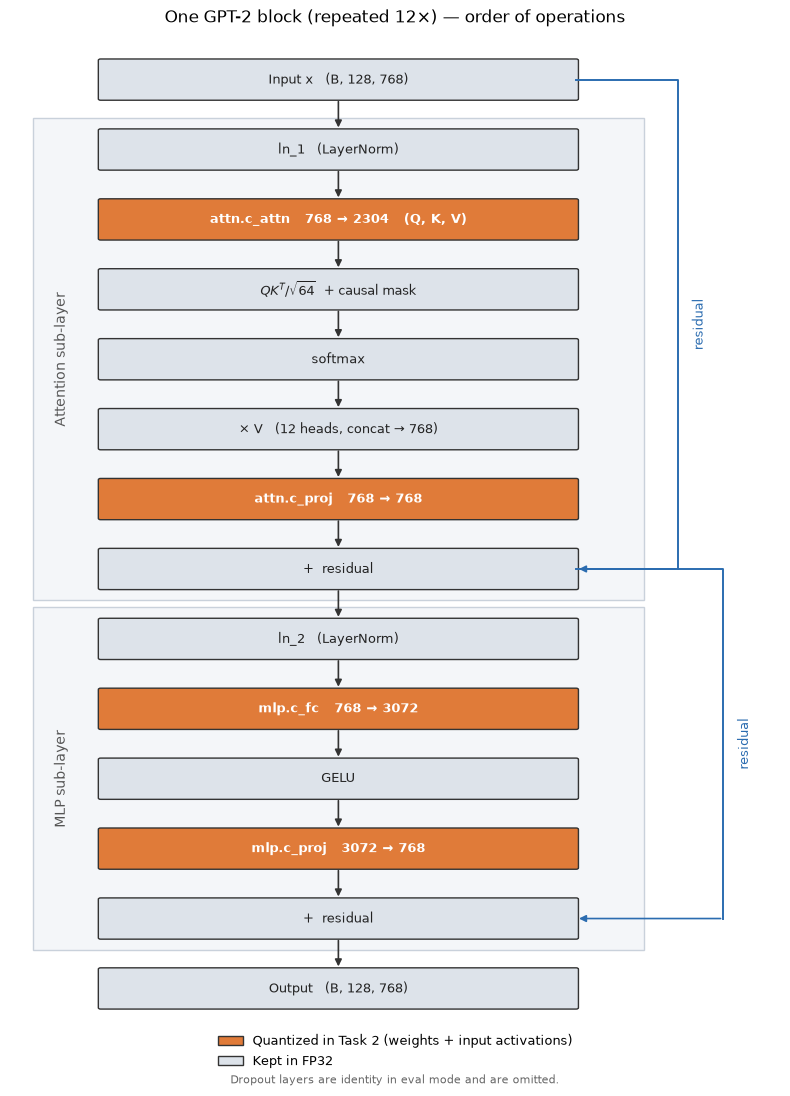

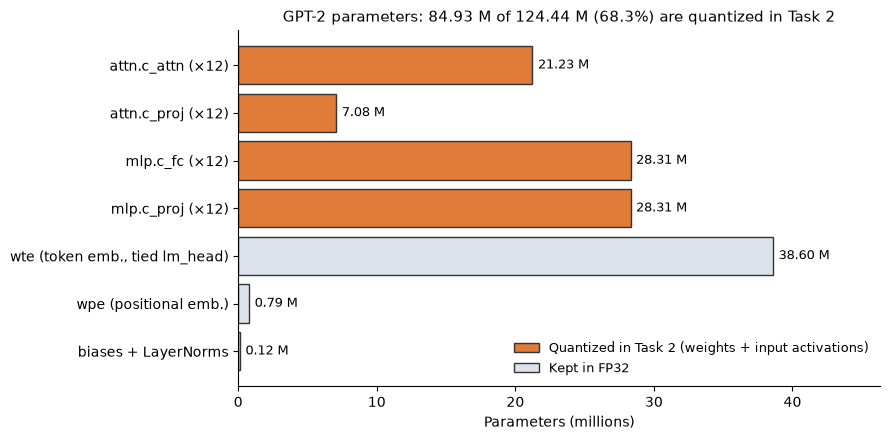

In [16]:
plot_model_overview()
plot_block_diagram()
plot_param_breakdown(model)

##  Task 1.2 — Baseline Language-Model Performance

## helper functions

In [ ]:
@torch.no_grad()
def nll_by_position(model, blocks, bs=EVAL_BS):
    total = torch.zeros(SEQ_LEN - 1)
    for i in range(0, len(blocks), bs):
        x = blocks[i:i+bs].to(DEVICE)
        logits = model(input_ids=x, use_cache=False).logits[:, :-1].float()
        loss = F.cross_entropy(logits.transpose(1, 2), x[:, 1:], reduction="none")  # (B, 127)
        total += loss.sum(0).cpu()
    return total / len(blocks)

## calling main function

In [19]:
os.makedirs("results", exist_ok=True)

model = load_fp32_model()                       

base_test = evaluate_lm(model, test_blocks)   
base_val  = evaluate_lm(model, val_blocks)     
pos_nll   = nll_by_position(model, test_blocks)

# Check every test target was scored exactly once
n_scored = base_test.get("scored_targets", base_test.get("targets"))
assert n_scored == test_info["scored_targets"], "Scored target count mismatch"

# Store for the final 13-row table (Task 2.4)
RESULTS = {"FP32 baseline": base_test}
json.dump(base_test, open("results/baseline_fp32.json", "w"), indent=2)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 5428.00it/s]


## results

=== Baseline GPT-2 (FP32) on WikiText-2 ===


,accuracy_%,nll,ppl,scored_targets
test (final),29.2843,4.2734,71.7626,283845
validation (reference),29.0705,4.2759,71.9466,247777


Scored targets: 283,845 = 2235 blocks × 127
Check: exp(NLL) = 71.7626  (= PPL)


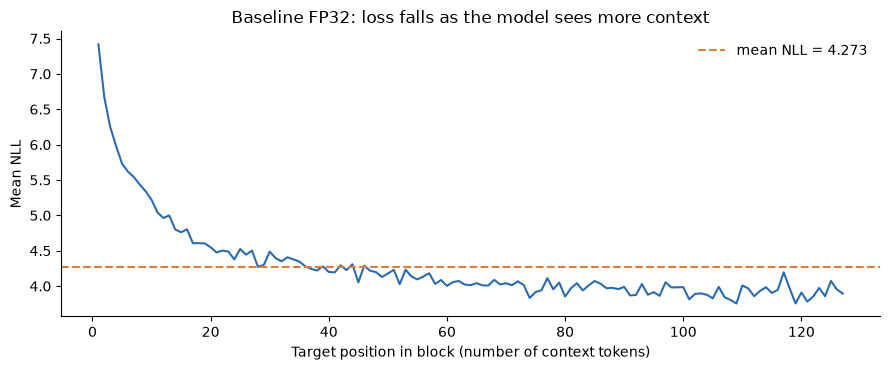

In [20]:
import matplotlib.pyplot as plt

print("=== Baseline GPT-2 (FP32) on WikiText-2 ===")
display(pd.DataFrame([base_test, base_val], index=["test (final)", "validation (reference)"]).round(4))
print(f"Scored targets: {n_scored:,} = {len(test_blocks)} blocks × 127")
print(f"Check: exp(NLL) = {math.exp(base_test['nll']):.4f}  (= PPL)")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(range(1, SEQ_LEN), pos_nll.numpy(), color="#2B6CB0", lw=1.5)
ax.axhline(base_test["nll"], ls="--", color="#E07B39", label=f"mean NLL = {base_test['nll']:.3f}")
ax.set_xlabel("Target position in block (number of context tokens)")
ax.set_ylabel("Mean NLL")
ax.set_title("Baseline FP32: loss falls as the model sees more context")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig("figures/t12_nll_by_position.png", dpi=200); plt.show()

## Task 1.3 — Baseline Profiling

### Functions

In [22]:
import os, time, resource, platform, subprocess, psutil
import matplotlib.pyplot as plt
from torch.profiler import profile, ProfilerActivity

N_WARMUP, N_MEASURE = 10, 30

def analytic_macs(cfg, L=SEQ_LEN, B=PROFILE_BS):
    """MACs per forward pass (dense attention). 1 MAC = 2 FLOPs."""
    d, h, n, V = cfg.n_embd, cfg.n_head, cfg.n_layer, cfg.vocab_size
    macs = {"Attention projections": n * B * L * (d * 3 * d + d * d),
            "Attention matmuls (QKᵀ, A·V)": n * B * 2 * h * L * L * (d // h),
            "MLP projections": n * B * L * (2 * d * 4 * d),
            "Vocabulary head": B * L * d * V}
    macs["Total"] = sum(macs.values())
    df = pd.DataFrame({"GMACs": {k: v / 1e9 for k, v in macs.items()}})
    df["GFLOPs"] = 2 * df["GMACs"]
    df["share_%"] = 100 * df["GMACs"] / df.loc["Total", "GMACs"]
    return df

def gpu_mem():
    return torch.mps.current_allocated_memory() if DEVICE == "mps" else \
           torch.cuda.memory_allocated() if DEVICE == "cuda" else 0

@torch.no_grad()
def profile_model(model, label):
    """Storage, compute, latency, memory for one model (batch 1, 128 tokens)."""
    model.eval()
    x = test_blocks[:PROFILE_BS].to(DEVICE)
    run = lambda: model(input_ids=x, use_cache=False)

    # Storage (tied weights counted once; torch.save stores shared tensors once)
    torch.save(model.state_dict(), "results/_tmp.pt")
    size_mb = os.path.getsize("results/_tmp.pt") / 1e6; os.remove("results/_tmp.pt")

    # Latency: 10 warm-up + 30 timed passes, synced (no profiler attached)
    for _ in range(N_WARMUP): run()
    sync()
    proc = psutil.Process(); proc.cpu_percent(None)
    times = []
    for _ in range(N_MEASURE):
        t0 = time.perf_counter(); run(); sync()
        times.append((time.perf_counter() - t0) * 1000)
    cpu_util = proc.cpu_percent(None)
    t = np.array(times)

    # Peak GPU memory: MPS has no peak counter, so sample after every module
    peak = [gpu_mem()]
    hooks = [m.register_forward_hook(lambda *_: peak.append(gpu_mem())) for m in model.modules()]
    run(); sync()
    for h in hooks: h.remove()

    # Profiler pass (separate from timing): FLOPs it can count + top operators
    with profile(activities=[ProfilerActivity.CPU], with_flops=True, record_shapes=True) as prof:
        run(); sync()
    ev = prof.key_averages()
    ops = pd.DataFrame([{"operator": e.key, "calls": e.count, "self CPU ms": e.self_cpu_time_total / 1000,
                         "GFLOPs": (e.flops or 0) / 1e9} for e in ev]) \
            .sort_values("self CPU ms", ascending=False).head(10).reset_index(drop=True)

    macs = analytic_macs(model.config).loc["Total", "GMACs"]
    maxrss = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return {
        "config": label,
        "unique_params_M": sum(p.numel() for p in model.parameters()) / 1e6,
        "serialized_MB": size_mb,
        "GMACs": macs, "GFLOPs": 2 * macs,
        "profiler_GFLOPs": sum(e.flops for e in ev if e.flops) / 1e9,
        "latency_mean_ms": t.mean(), "latency_std_ms": t.std(ddof=1),
        "seq_per_s": 1000 * PROFILE_BS / t.mean(), "tokens_per_s": 1000 * x.numel() / t.mean(),
        "peak_gpu_alloc_MB": max(peak) / 1e6,
        "gpu_driver_MB": torch.mps.driver_allocated_memory() / 1e6 if DEVICE == "mps" else float("nan"),
        "peak_process_rss_MB": maxrss / 1e6 if platform.system() == "Darwin" else maxrss / 1e3,
        "cpu_util_%_one_core": cpu_util,
        "gpu_util_%": "unavailable", "power_W": "unavailable", "energy_mJ": "unavailable",
    }, ops

def environment_info():
    sh = lambda c: subprocess.run(c, shell=True, capture_output=True, text=True).stdout.strip() or "unavailable"
    return pd.Series({
        "CPU / SoC": sh("sysctl -n machdep.cpu.brand_string"),
        "GPU": sh("system_profiler SPDisplaysDataType | grep 'Chipset Model' | cut -d: -f2"),
        "Unified memory (GB)": round(psutil.virtual_memory().total / 1e9, 1),
        "OS": platform.platform(), "PyTorch": torch.__version__,
        "Transformers": transformers.__version__, "Device": DEVICE}, name="value")

### calling main functions

In [23]:
os.makedirs("results", exist_ok=True)
model = load_fp32_model()

base_prof, base_ops = profile_model(model, "FP32 baseline")
mac_df = analytic_macs(model.config)
env = environment_info()

PROFILES = {"FP32 baseline": base_prof}           # reused in Task 2.4
json.dump(base_prof, open("results/baseline_profile.json", "w"), indent=2, default=str)

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 8313.23it/s]
USDT:2026-10-18 16:15:24 34337:5072052 SyncActivityProfilerHandler.cpp:39] profiler_start
USDT:2026-10-18 16:15:24 34337:5072052 SyncActivityProfilerHandler.cpp:46] profiler_stop


### results

=== Baseline profile (batch 1, 128 tokens, 10 warm-up + 30 measured) ===


,value
config,FP32 baseline
unique_params_M,124.439808
serialized_MB,497.803017
GMACs,16.11409
GFLOPs,32.22818
profiler_GFLOPs,21.774041
latency_mean_ms,14.052816
latency_std_ms,0.70763
seq_per_s,71.160112
tokens_per_s,9108.494375



=== MACs / FLOPs per forward pass ===


,GMACs,GFLOPs,share_%
Attention projections,3.624,7.248,22.489
"Attention matmuls (QKᵀ, A·V)",0.302,0.604,1.874
MLP projections,7.248,14.496,44.978
Vocabulary head,4.940,9.881,30.659
Total,16.114,32.228,100.000


Profiler counted 21.77 GFLOPs vs analytic 32.23. The gap is the fused attention matmuls, which the profiler does not count; they are added analytically.

=== Top 10 operators (profiler) ===


,operator,calls,self CPU ms,GFLOPs
0,aten::addmm,48,1.917,21.743
1,aten::view,228,0.791,0.000
2,aten::_local_scalar_dense,1,0.668,0.000
3,aten::diff,1,0.248,0.000
4,aten::arange,2,0.244,0.000
5,aten::add,50,0.233,0.012
6,aten::_to_copy,49,0.183,0.000
7,aten::mul,48,0.169,0.019
8,aten::native_layer_norm,25,0.113,0.000
9,aten::linear,1,0.106,0.000



=== Environment ===


,value
CPU / SoC,Apple M2 Pro
GPU,Apple M2 Pro
Unified memory (GB),17.2
OS,macOS-26.6.2-arm64-arm-64bit-Mach-O
PyTorch,2.14.1
Transformers,5.20.1
Device,mps


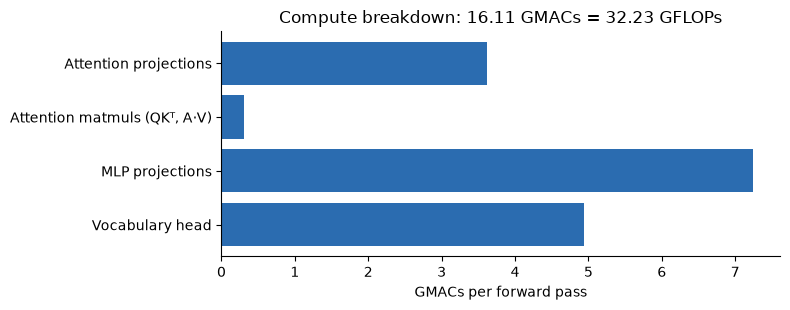

In [24]:
print("=== Baseline profile (batch 1, 128 tokens, 10 warm-up + 30 measured) ===")
display(pd.Series(base_prof).to_frame("value"))

print("\n=== MACs / FLOPs per forward pass ===")
display(mac_df.round(3))
print(f"Profiler counted {base_prof['profiler_GFLOPs']:.2f} GFLOPs vs analytic {base_prof['GFLOPs']:.2f}. "
      "The gap is the fused attention matmuls, which the profiler does not count; they are added analytically.")

print("\n=== Top 10 operators (profiler) ===")
display(base_ops.round(3))

print("\n=== Environment ===")
display(env.to_frame())

parts = mac_df.drop("Total")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(parts.index[::-1], parts["GMACs"][::-1], color="#2B6CB0")
ax.set_xlabel("GMACs per forward pass")
ax.set_title(f"Compute breakdown: {mac_df.loc['Total','GMACs']:.2f} GMACs = {mac_df.loc['Total','GFLOPs']:.2f} GFLOPs")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig("figures/t13_mac_breakdown.png", dpi=200); plt.show()